In [74]:
# 그래프 관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

# 판다스 관련 import
import pandas as pd
import numpy as np

# 인공지능 import
from sklearn import svm,metrics # 분류와 숫자 예측에 사용하는 모델 모음,모델의 예측 성능을 평가하는 도구 모음
from sklearn.neighbors import KNeighborsClassifier  #분류(가까운 이웃 데이터를 참고해 종류를 분류)
from sklearn.neighbors import KNeighborsRegressor   #예측(가까운 이웃데이터를 참고해 숫자를 예측)

from sklearn.preprocessing import PolynomialFeatures # 다항특성 (x², x₁ × x₂ 같은 특성을 추가)
from sklearn.preprocessing import OneHotEncoder      # 원핫인코딩(문자형 번주를 0과1로 변환)

from sklearn.linear_model import LinearRegression   #예측 (입력과 결과의 선형관례를 학습해 숫자를 예측)
from sklearn.linear_model import Ridge              #릿지 (계수가 지나치게 커지는 것을 억제하는 선형 회귀)
from sklearn.linear_model import Lasso              #라쏘 (일부 계수를 0으로 만들어 특성 선택에도 활용하는 선형 회귀)
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위 (실제값과 예측값의 차이를 절댓값으로 구한 뒤 평균 계산)
from sklearn.preprocessing import StandardScaler # 표준화 (각 특성을 평균 0, 표준편차 1 기준으로 표준화)
from sklearn.model_selection import train_test_split #(데이터를 학습용과 평가용으로 분리)
from scipy.special import expit                     #exip:이진분류함수
from scipy.special import softmax                   #softmax: 다중분류함수

In [75]:
# logisticRegression 이진분류 -> 다중분류

fish= pd.read_csv('data/fish_logistic.csv')
fish.head(2)

,Species,Weight,Length,Diagonal,Height,Width
0,Bream,242.0,25.4,30.0,11.52,4.0200
1,Bream,290.0,26.3,31.2,12.48,4.3056


In [76]:
fish['Species'].unique() # 7개의 특성(종류)를 가지고 있음
# ['Bream', 'Roach', 'Whitefish', 'Parkki', 'Perch', 'Pike', 'Smelt']

<StringArray>
['Bream', 'Roach', 'Whitefish', 'Parkki', 'Perch', 'Pike', 'Smelt']
Length: 7, dtype: str

In [77]:
# 데이터 전처리
data=fish[fish.columns[1:]].values
data[0] # array([242.  ,  25.4 ,  30.  ,  11.52,   4.02])
label = fish['Species'].values

In [78]:
# 학습/테스트 데이터 분리
train_data, test_data, train_label, test_label = train_test_split(data, label, stratify=label, random_state=42)

In [79]:
# logisticRegression전 정규화 작업 필수
# 정규화 작업
ss=StandardScaler()
ss.fit(train_data)

train_scaled= ss.transform(train_data)
test_scaled= ss.transform(test_data)

In [80]:
# 다중 분류
# C(대문자표기, 매개변수)- alpah, C 구제, C가 높아질수록 완화, 낮아질수록 강화, 디폴트가 20
# alpah for문으로 그래프로 가장 최적화된 구제를 찾아서 적용.
# max_iter 반복을 자동화해주는 매개변수
lr=LogisticRegression(C=20, max_iter=1000)
lr.fit(train_scaled, train_label)
print()

In [83]:
# 다중 분류
# C(대문자표기, 매개변수)- alpah, C 구제, C가 높아질수록 완화, 낮아질수록 강화, 디폴트가 20
# alpah for문으로 그래프로 가장 최적화된 구제를 찾아서 적용.
# max_iter 반복을 자동화해주는 매개변수
train_score=[]
test_score=[]
cc=[0.001,0.01,0.1,1,10,20,50,100]
for c in cc:
    lr=LogisticRegression(C=c, max_iter=1000)
    lr.fit(train_scaled, train_label)
    train_score.append(lr.score(train_scaled, train_label))
    test_score.append(lr.score(test_scaled, test_label))


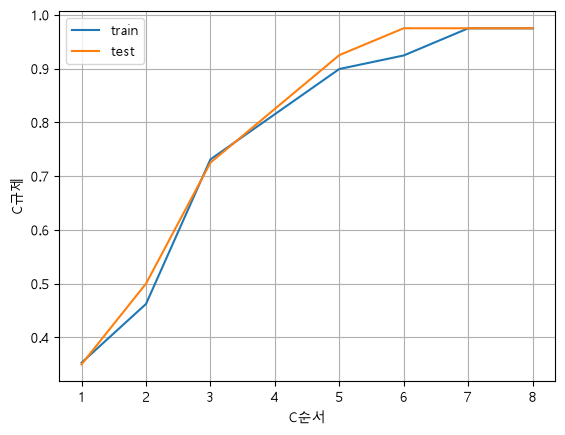

In [86]:
# C규제 선그래프
list1=[1,2,3,4,5,6,7,8]

plt.plot(list1,train_score )
plt.plot(list1,test_score )
plt.xlabel('C순서')
plt.ylabel('C규제')
plt.legend(['train','test'])
plt.grid()
plt.show()

In [ ]:
lr.classes_

array(['Bream', 'Parkki', 'Perch', 'Pike', 'Roach', 'Smelt', 'Whitefish'],
      dtype=object)

In [ ]:
lr.predict_proba(test_scaled[:5])

decisions= lr.decision_function(test_scaled[:5])
# decisions # 'Bream', 'Parkki', 'Perch', 'Pike', 'Roach', 'Smelt', 'Whitefish' 순으로 확률이 나옴


soft1=softmax(decisions, axis=1) #행방향
np.round(soft1, decimals=3) # 소수점 3자리가지 보여줘.

array([[0.   , 0.029, 0.237, 0.003, 0.685, 0.01 , 0.035],
       [0.   , 0.032, 0.577, 0.001, 0.349, 0.003, 0.039],
       [0.   , 0.062, 0.559, 0.001, 0.335, 0.017, 0.026],
       [0.003, 0.93 , 0.001, 0.   , 0.051, 0.   , 0.015],
       [0.001, 0.882, 0.004, 0.   , 0.094, 0.002, 0.017]])

In [ ]:
print('train정확도:',lr.score(train_scaled, train_label))
print('test정확도:',lr.score(test_scaled, test_label))

train정확도: 0.9243697478991597
test정확도: 0.975


In [ ]:
fish[:2]

,Species,Weight,Length,Diagonal,Height,Width
0,Bream,242.0,25.4,30.0,11.52,4.0200
1,Bream,290.0,26.3,31.2,12.48,4.3056


In [ ]:
# 생선의 무게, 길이, 대각선, 높이, 넓이를 입력받아, 어떤생선인지 분류확률을 출력하시오
# 예 : 150.    ,  22.    ,  24.7   ,   5.8045,   3.7544
# 분류생선과 확률을 출력하시오
# 분류생선 : 93.1% 의 확률로 Bream 판별됩니다.

In [ ]:
# 'Bream', 'Parkki', 'Perch', 'Pike', 'Roach', 'Smelt', 'Whitefish' 순으로 확률이 나옴

In [ ]:
in_data = '242.0,25.4,30.0,11.52,4.0200'
# in_data = '55,14.7,16.5,6.8475,2.3265'
# in_data = '32,13.7,14.7,3.528,1.9992'
# in_data = '300,35,38.8,5.9364,4.3844'
in_data=list(map(float,in_data.split(',')))

# logisticRegression전 정규화 작업 필수
# 정규화 작업
ss=StandardScaler()
ss.fit(train_data)

in_data_scaled= ss.transform([in_data])


In [ ]:
lr=LogisticRegression()
lr.fit(train_scaled, train_label)

# 종류
predict= lr.predict(in_data_scaled)
print(predict)

# 확률
decisions= lr.decision_function(in_data_scaled)
decisions=softmax(decisions, axis=1) #행방향
# np.round(decisions, decimals=3) # 소수점 3자리가지 보여줘.

if predict[0]=="Bream":
    proba=decisions[0][0]
elif predict[0]=="Parkki":
    proba=decisions[0][1]
elif predict[0]=="Perch":
    proba=decisions[0][2]
elif predict[0]=="Pike":
    proba=decisions[0][3]
elif predict[0]=="Roach":
    proba=decisions[0][4]
elif predict[0]=="Smelt":
    proba=decisions[0][5]
else:
    proba=decisions[0][6]

print(f'분류생선 : {proba*100:.2f}% 의 확률로 {predict[0]} 판별됩니다.')

['Bream']
분류생선 : 48.88% 의 확률로 Bream 판별됩니다.
